# Family Credit Card Debt by Income and Age

This project examines how credit card debt varies among U.S. families by family income and by the age of the family’s reference person. It asks two questions: What percentage of families in each group carry credit card debt? Among families carrying debt, what is the typical balance? Looking at both measures shows whether debt is most common in the same groups where families with debt tend to owe the most.

The analysis uses public data from the Federal Reserve’s 2022 Survey of Consumer Finances. It applies survey weights and combines estimates from all five imputed datasets to calculate the share of families carrying debt and the weighted median balance among families with debt. The results are presented by income and age, with a heatmap showing how debt prevalence varies when the two factors are considered together. All amounts are expressed in 2025 dollars.


Data Source:   https://www.federalreserve.gov/econres/scf_2022.htm

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import StrMethodFormatter


In [6]:
#Load Dataset

df= pd.read_csv("SCFP2022.csv")

df .head()

,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
0,1,11,3027.956120,2,70,5,9,3,2,2,...,4,2,4,2,1,8,3,3,2,1
1,1,12,3054.900065,2,70,5,9,3,2,2,...,4,2,5,2,1,8,3,3,2,1
2,1,13,3163.637766,2,70,5,9,3,2,2,...,4,2,4,2,1,8,3,3,1,1
3,1,14,3166.228463,2,70,5,9,3,2,2,...,3,2,4,1,1,6,3,2,1,1
4,1,15,3235.624715,2,70,5,9,3,2,2,...,3,2,4,2,1,8,3,3,1,1


CCBAL	-Credit card balance in dollars	Measures the amount owed. A positive balance also flags a family as carrying debt.

HCCBAL	-Has a credit card balance (0 = no, 1 = yes)	We used it to verify that CCBAL > 0 correctly identifies records with debt.

INCOME	-Family income	Groups families into income bands for the main comparison.

NORMINC	-Normal family income, or what the family usually earns	Helps distinguish usual income from income in the survey’s reporting period.

AGECL	-Age category of the family’s reference person	Groups families into age bands. This is the next field we’ll inspect.

EDCL	-Education category of the reference person	Lets us compare debt across education groups.

KIDS	-Number of children in the household	Lets us compare families with and without children present.

NETWORTH	-Net worth, calculated as assets minus debts	Lets us compare families with negative net worth to those with zero or positive net worth.

DEBT	-Total family debt across debt types	Gives context for how credit card debt fits into overall borrowing.

WGT	-Survey weight	Helps turn survey records into estimates for U.S. families.

YY1	-Family case ID	Identifies the same family across its five imputed records.

Y1	-Case ID that includes the imputation number

The inventory below shows every field, in file order, with its data type and missing-value count.

In [7]:
inventory = pd.DataFrame({
    'Type': df.dtypes.astype(str),
    'Missing values': df.isna().sum()
})
with pd.option_context('display.max_rows', None):
    display(inventory)

,Type,Missing values
YY1,int64,0
Y1,int64,0
WGT,float64,0
HHSEX,int64,0
AGE,int64,0
AGECL,int64,0
EDUC,int64,0
EDCL,int64,0
MARRIED,int64,0
KIDS,int64,0


In [8]:
#Summary -quick first look at the numeric columns


display(df.select_dtypes('number').describe().T
        .sort_values('max', ascending=False).head(12).round(2))

,count,mean,std,min,25%,50%,75%,max
NETWORTH,22975.0,21839857.29,1.205685e+08,-6.079272e+05,39296.39,420788.51,2709795.90,2.613136e+09
ASSET,22975.0,22234537.14,1.213946e+08,0.000000e+00,69876.06,590745.48,2973316.75,2.613136e+09
NHNFIN,22975.0,13045446.57,8.226819e+07,-3.593000e+02,15569.63,51499.56,551135.10,2.324401e+09
FIN,22975.0,9253700.50,7.091567e+07,0.000000e+00,5838.51,104513.14,1112999.28,2.319778e+09
NFIN,22975.0,12980836.64,7.683434e+07,0.000000e+00,35020.11,409078.66,1439107.63,2.139892e+09
BUS,22975.0,9960733.76,6.689333e+07,-3.283100e+02,0.00,0.00,3283.14,2.087899e+09
EQUITY,22975.0,6417786.61,6.067321e+07,0.000000e+00,0.00,18604.43,519829.75,2.068627e+09
STOCKS,22975.0,3658764.50,5.426434e+07,0.000000e+00,0.00,0.00,4103.92,1.992414e+09
DEQ,22975.0,5309904.83,5.812149e+07,0.000000e+00,0.00,0.00,71134.60,1.992414e+09
NONACTBUS,22975.0,2303850.28,2.927640e+07,0.000000e+00,0.00,0.00,0.00,1.658903e+09


In [10]:
#inspect one candidate field at a time

display(
    df["HCCBAL"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("HCCBAL code")
    .to_frame("Record count")
)

,Record count
HCCBAL code,
0,14281
1,8694


14,281 records coded 0 (no credit card debt) and 8,694 coded 1 (has credit card debt). These are unweighted record counts.

In [11]:
#Check whether HCCBAL agrees with CCBAL
display(pd.crosstab(
    df["HCCBAL"],
    df["CCBAL"] > 0,
    rownames=["HCCBAL code"],
    colnames=["Balance is greater than zero"]
))

Balance is greater than zero,False,True
HCCBAL code,,
0,14281,0
1,0,8694


CCBAL in the working dataset because it gives us both the amount owed and the debt flag (CCBAL > 0).

In [12]:
#Inspect the age-group codes

age_counts = df["AGECL"].value_counts(dropna=False).sort_index()

display(age_counts.rename_axis("AGECL code").to_frame("Record count"))

,Record count
AGECL code,
1,3065
2,3815
3,4100
4,5130
5,4330
6,2535


In [13]:
#Show the age ranges beside the codes
age_labels = {
    1: "Under 35",
    2: "35–44",
    3: "45–54",
    4: "55–64",
    5: "65–74",
    6: "75 and older"
}

age_table = age_counts.rename_axis("AGECL code").reset_index(name="Record count")
age_table["Age group"] = age_table["AGECL code"].map(age_labels)

display(age_table[["AGECL code", "Age group", "Record count"]])

,AGECL code,Age group,Record count
0,1,Under 35,3065
1,2,35–44,3815
2,3,45–54,4100
3,4,55–64,5130
4,5,65–74,4330
5,6,75 and older,2535


In [14]:
#Check for zero or negative income

income = df["INCOME"]

income_check = pd.Series({
    "Negative income": income.lt(0).sum(),
    "Zero income": income.eq(0).sum(),
    "Positive income": income.gt(0).sum(),
    "Missing income": income.isna().sum()
}, name="Record count")

display(income_check.to_frame())

,Record count
Negative income,0
Zero income,197
Positive income,22778
Missing income,0


In [15]:
#Create income bands and display their counts
income_bins = [0, 25_000, 50_000, 100_000, 200_000, float("inf")]
income_labels = [
    "Under $25,000",
    "$25,000 to under $50,000",
    "$50,000 to under $100,000",
    "$100,000 to under $200,000",
    "$200,000 and above"
]

income_group = pd.cut(
    df["INCOME"], bins=income_bins, labels=income_labels, right=False
)

display(income_group.value_counts(sort=False, dropna=False)
        .rename_axis("Income band").to_frame("Record count"))

,Record count
Income band,
"Under $25,000",2682
"$25,000 to under $50,000",3690
"$50,000 to under $100,000",4899
"$100,000 to under $200,000",4382
"$200,000 and above",7322


In [16]:
#Check how many records belong to each family

records_per_family = df.groupby("YY1", dropna=False).size()

display(
    records_per_family.value_counts()
    .sort_index()
    .rename_axis("Records per family")
    .to_frame("Number of families")
)

,Number of families
Records per family,
5,4595


In [17]:
#Identify the five imputations

implicate = df["Y1"] % 10

display(
    implicate.value_counts(dropna=False)
    .sort_index()
    .rename_axis("Imputation number")
    .to_frame("Record count")
)

,Record count
Imputation number,
1,4595
2,4595
3,4595
4,4595
5,4595


In [18]:
#Check for repeated family–imputation pairs

family_imputations = pd.DataFrame({
    "Family ID": df["YY1"],
    "Imputation number": implicate
})

repeated_pairs = family_imputations.duplicated().sum()
print(f"Repeated family–imputation pairs: {repeated_pairs}")

Repeated family–imputation pairs: 0


Zero repeated pairs confirms that all 4,595 families appear exactly once in each of the five imputations.

In [19]:
#Check the survey weights

weights = df["WGT"]

weight_check = pd.Series({
    "Missing weights": weights.isna().sum(),
    "Zero or negative weights": weights.le(0).sum(),
    "Smallest weight": weights.min(),
    "Largest weight": weights.max()
})

display(weight_check.to_frame("Value").round(2))

,Value
Missing weights,0.00
Zero or negative weights,0.00
Smallest weight,2.75
Largest weight,28265.28


In [20]:
#Inspect the education codes
education_counts = df["EDCL"].value_counts(dropna=False).sort_index()

display(
    education_counts.rename_axis("EDCL code").to_frame("Record count")
)

,Record count
EDCL code,
1,2146
2,4522
3,4939
4,11368


Keeping the survey codes beside their labels makes the mapping easy to check. We’ll reuse those labels when we compare the weighted share of families carrying credit card debt by education group.

In [21]:
#Add readable education labels
education_labels = {
    1: "No high school diploma",
    2: "High school diploma",
    3: "Some college",
    4: "College degree"
}

education_table = education_counts.rename_axis("EDCL code").reset_index(
    name="Record count"
)
education_table["Education group"] = education_table["EDCL code"].map(education_labels)

display(education_table[["EDCL code", "Education group", "Record count"]])

,EDCL code,Education group,Record count
0,1,No high school diploma,2146
1,2,High school diploma,4522
2,3,Some college,4939
3,4,College degree,11368


In [22]:
#Inspect the number of children
children_counts = df["KIDS"].value_counts(dropna=False).sort_index()

display(
    children_counts.rename_axis("Number of children")
    .to_frame("Record count")
)

,Record count
Number of children,
0,13820
1,4090
2,3205
3,1225
4,480
5,95
6,40
7,10
8,5


There are 13,820 records with no children and 9,155 with one or more children. Some exact-count categories are small. For example, only five records show eight children. We’ll use two broader groups for the debt comparison.

In [23]:
#Create and display the two groups
children_group = df["KIDS"].gt(0).map({
    False: "No children present",
    True: "One or more children present"
})

display(
    children_group.value_counts()
    .rename_axis("Children in household")
    .to_frame("Record count")
)

,Record count
Children in household,
No children present,13820
One or more children present,9155


In [24]:
#Check for negative, zero, and positive net worth
net_worth = df["NETWORTH"]

net_worth_check = pd.Series({
    "Negative net worth": net_worth.lt(0).sum(),
    "Zero net worth": net_worth.eq(0).sum(),
    "Positive net worth": net_worth.gt(0).sum(),
    "Missing net worth": net_worth.isna().sum()
}, name="Record count")

display(net_worth_check.to_frame())

,Record count
Negative net worth,1582
Zero net worth,101
Positive net worth,21292
Missing net worth,0


There are 1,582 records with negative net worth and 101 with exactly zero. We’ll group zero with positive net worth so the comparison answers a clear question: Do families whose debts exceed their assets carry credit card debt more often?

In [25]:
#Create and display the two net worth groups
net_worth_group = df["NETWORTH"].lt(0).map({
    True: "Negative net worth",
    False: "Zero or positive net worth"
})

display(
    net_worth_group.value_counts()
    .rename_axis("Net worth group")
    .to_frame("Record count")
)

,Record count
Net worth group,
Zero or positive net worth,21393
Negative net worth,1582


The net worth groups account for all 22,975 records. Now that we’ve inspected the fields and checked the survey structure, we can create the working dataset.

In [26]:
#Select the columns for analysis
selected_columns = [
    "YY1", "WGT", "CCBAL", "AGECL", "INCOME",
    "EDCL", "KIDS", "NETWORTH"
]

analysis_df = df[selected_columns].copy()
analysis_df["Imputation"] = implicate

display(analysis_df.head())
print(f"{analysis_df.shape[0]:,} rows and {analysis_df.shape[1]} columns")

,YY1,WGT,CCBAL,AGECL,INCOME,EDCL,KIDS,NETWORTH,Imputation
0,1,3027.956120,0.0,5,42467.064299,3,2,834025.79982,1
1,1,3054.900065,0.0,5,41875.601008,3,2,934927.49086,2
2,1,3163.637766,0.0,5,39509.747843,3,2,742207.44973,3
3,1,3166.228463,0.0,5,36670.724046,3,2,305988.20841,4
4,1,3235.624715,0.0,5,38918.284552,3,2,659472.44059,5


22,975 rows and 9 columns


The first five rows show the five imputed records for family YY1 = 1. Its income and net worth vary across imputations, while its credit card balance is zero in all five.

In [27]:
#Add a credit card debt flag
analysis_df["Has credit card debt"] = analysis_df["CCBAL"] > 0

debt_counts = analysis_df["Has credit card debt"].value_counts().sort_index()
debt_counts = debt_counts.rename(index={False: "No", True: "Yes"})

display(
    debt_counts.rename_axis("Has credit card debt")
    .to_frame("Record count")
)

,Record count
Has credit card debt,
No,14281
Yes,8694


In [28]:
#Calculate the weighted debt rate for each imputation

analysis_df["Weight for families with debt"] = (
    analysis_df["WGT"] * analysis_df["Has credit card debt"]
)

weighted_totals = analysis_df.groupby("Imputation")[
    ["WGT", "Weight for families with debt"]
].sum()

weighted_totals["Carrying credit card debt (%)"] = (
    100 * weighted_totals["Weight for families with debt"] / weighted_totals["WGT"]
)

display(weighted_totals.round(2))

,WGT,Weight for families with debt,Carrying credit card debt (%)
Imputation,,,
1,26261278.16,11952829.18,45.52
2,26261278.17,11821886.22,45.02
3,26261277.83,11859644.43,45.16
4,26261277.23,11851114.91,45.13
5,26261277.99,11894846.13,45.29


The five weighted rates range from 45.02% to 45.52%. 

In [29]:
#Calculate the national credit card debt rate

national_debt_rate = weighted_totals["Carrying credit card debt (%)"].mean()

print(f"Estimated share of U.S. families carrying credit card debt: {national_debt_rate:.2f}%")

Estimated share of U.S. families carrying credit card debt: 45.22%


In [30]:
#Find the weighted median balance for imputation 1
debtors_1 = analysis_df.loc[
    analysis_df["Imputation"].eq(1) & analysis_df["Has credit card debt"],
    ["CCBAL", "WGT"]
].sort_values("CCBAL")

debtors_1["Cumulative weight"] = debtors_1["WGT"].cumsum()
half_weight = debtors_1["WGT"].sum() / 2

median_row = debtors_1.loc[
    debtors_1["Cumulative weight"] >= half_weight
].head(1)

print(f"Half of the total weight: {half_weight:,.2f}")
display(median_row.round(2))

Half of the total weight: 5,976,414.59


,CCBAL,WGT,Cumulative weight
4410,2889.16,1389.12,5976792.69


The cumulative weight first crosses 5,976,414.59 at a balance of $2,889.16. That’s the weighted median for imputation 1.

In [31]:
#Calculate the weighted median for all five imputations
def weighted_median_balance(group):
    debtors = group.loc[group["Has credit card debt"]].sort_values("CCBAL")
    cumulative_weight = debtors["WGT"].cumsum()
    half_weight = debtors["WGT"].sum() / 2

    return debtors.loc[cumulative_weight >= half_weight, "CCBAL"].iloc[0]


median_balances = pd.Series({
    number: weighted_median_balance(group)
    for number, group in analysis_df.groupby("Imputation")
}, name="Weighted median balance ($)")

display(median_balances.rename_axis("Imputation").to_frame().round(2))

,Weighted median balance ($)
Imputation,
1,2889.16
2,2954.82
3,2954.82
4,2954.82
5,2954.82


Imputation 1 matches your manual check of $2,889.16. The other four imputations each have a weighted median of $2,954.82.

In [32]:
#Combine the five weighted medians

national_median_balance = median_balances.mean()

print(f"Median balance among families carrying credit card debt: "
      f"${national_median_balance:,.2f} (2025 dollars)")

Median balance among families carrying credit card debt: $2,941.69 (2025 dollars)


In [33]:
#Add the income bands to the working dataset
analysis_df["Income band"] = income_group

income_counts = (
    analysis_df.groupby(["Income band", "Imputation"], observed=True)
    .size()
    .unstack("Imputation", fill_value=0)
)

display(income_counts)

Imputation,1,2,3,4,5
Income band,,,,,
"Under $25,000",538,533,538,537,536
"$25,000 to under $50,000",737,744,736,732,741
"$50,000 to under $100,000",978,977,978,993,973
"$100,000 to under $200,000",873,878,885,861,885
"$200,000 and above",1469,1463,1458,1472,1460


Each imputation column adds up to 4,595 families. The counts vary slightly across imputations because a family’s income can move across a band boundary.


In [34]:
#Calculate the weighted debt rate by income band
income_weighted_totals = (
    analysis_df.groupby(["Income band", "Imputation"], observed=True)[
        ["WGT", "Weight for families with debt"]
    ].sum()
)

income_debt_rates = (
    100 * income_weighted_totals["Weight for families with debt"]
    / income_weighted_totals["WGT"]
).unstack("Imputation")

display(income_debt_rates.round(2))

Imputation,1,2,3,4,5
Income band,,,,,
"Under $25,000",29.88,29.37,28.28,28.94,29.96
"$25,000 to under $50,000",46.29,45.15,45.39,45.54,45.33
"$50,000 to under $100,000",53.09,53.84,53.91,53.59,52.74
"$100,000 to under $200,000",53.57,52.57,53.15,53.17,54.19
"$200,000 and above",31.76,31.61,31.39,31.50,31.48


In [35]:
#Average the five rates for each income band

income_summary = (
    income_debt_rates.mean(axis=1)
    .to_frame("Carrying credit card debt (%)")
)

income_summary["Difference from national rate (pp)"] = (
    income_summary["Carrying credit card debt (%)"] - national_debt_rate
)

display(income_summary.round(2))

,Carrying credit card debt (%),Difference from national rate (pp)
Income band,,
"Under $25,000",29.29,-15.94
"$25,000 to under $50,000",45.54,0.32
"$50,000 to under $100,000",53.43,8.21
"$100,000 to under $200,000",53.33,8.11
"$200,000 and above",31.55,-13.68


The $50,000 to under $100,000 and $100,000 to under $200,000 bands had the highest estimated debt rates, at 53.43% and 53.33%. Both were about 8 percentage points above the national rate.

In [36]:
#Calculate the weighted median balance by income band and imputation

income_median_balances = (
    analysis_df.groupby(["Income band", "Imputation"], observed=True)[
        ["CCBAL", "WGT", "Has credit card debt"]
    ]
    .apply(weighted_median_balance)
    .unstack("Imputation")
)

display(income_median_balances.round(2))

Imputation,1,2,3,4,5
Income band,,,,,
"Under $25,000",2188.76,2188.76,2188.76,2188.76,2188.76
"$25,000 to under $50,000",1422.69,1422.69,1422.69,1422.69,1422.69
"$50,000 to under $100,000",2407.63,2298.19,2692.17,2462.35,2462.35
"$100,000 to under $200,000",4377.51,4486.95,4377.51,4377.51,4377.51
"$200,000 and above",5471.89,5471.89,5471.89,6019.08,6128.52


In [37]:
#Add the median balances to the income summary

income_summary["Weighted median balance ($)"] = (
    income_median_balances.mean(axis=1)
)

display(income_summary.round(2))

,Carrying credit card debt (%),Difference from national rate (pp),Weighted median balance ($)
Income band,,,
"Under $25,000",29.29,-15.94,2188.76
"$25,000 to under $50,000",45.54,0.32,1422.69
"$50,000 to under $100,000",53.43,8.21,2464.54
"$100,000 to under $200,000",53.33,8.11,4399.40
"$200,000 and above",31.55,-13.68,5712.66


>> table shows that credit card debt was most common among families earning $50,000 to under $100,000 (53.43%). Among families who carried debt, the $200,000 and above group had the highest weighted median balance ($5,712.66), with a debt rate of 31.55%.

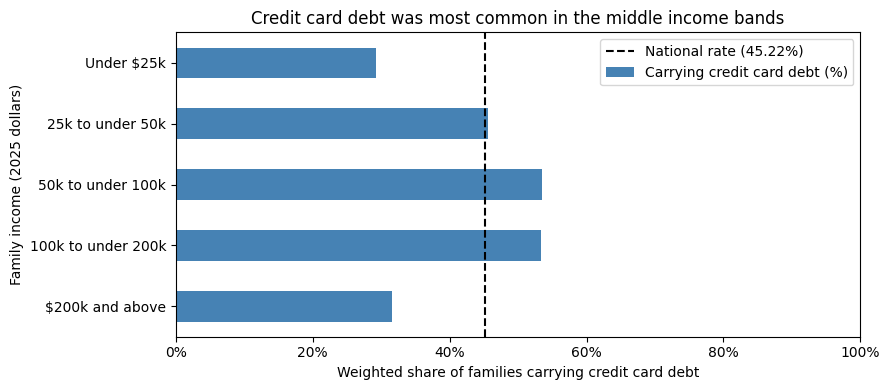

In [40]:
#Plot the debt rate by income band

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ax = income_summary["Carrying credit card debt (%)"].plot.barh(
    figsize=(9, 4),
    color="steelblue"
)

ax.axvline(
    national_debt_rate,
    color="black",
    linestyle="--",
    label=f"National rate ({national_debt_rate:.2f}%)"
)

ax.set_title("Credit card debt was most common in the middle income bands")
ax.set_xlabel("Weighted share of families carrying credit card debt")
ax.set_ylabel("Family income (2025 dollars)")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_yticks(range(len(income_summary)), [
    "Under $25k", "25k to under 50k", "50k to under 100k",
    "100k to under 200k", "$200k and above"
])
ax.legend()

plt.tight_layout()
plt.show()

>>The chart shows the two middle-income bands above the 45.22% national rate.

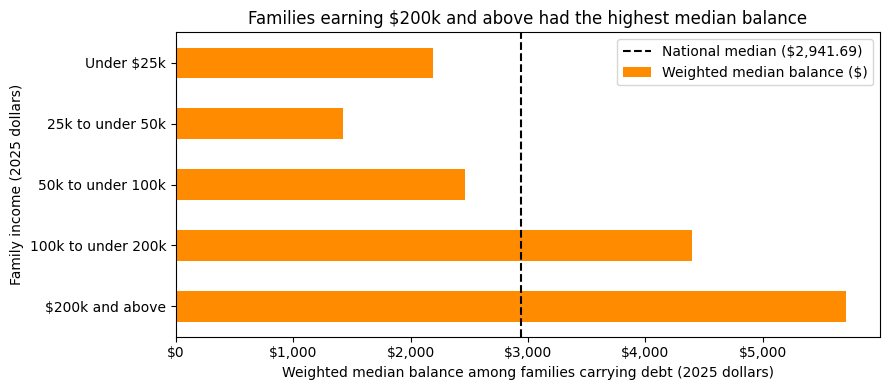

In [41]:
#Plot the median balance among families carrying debt

from matplotlib.ticker import StrMethodFormatter

income_chart_labels = [
    "Under $25k", "25k to under 50k", "50k to under 100k",
    "100k to under 200k", "$200k and above"
]

ax = income_summary["Weighted median balance ($)"].plot.barh(
    figsize=(9, 4), color="darkorange", legend=False
)

ax.set_yticks(range(len(income_chart_labels)), income_chart_labels)
ax.axvline(
    national_median_balance,
    color="black",
    linestyle="--",
    label=f"National median (${national_median_balance:,.2f})"
)
ax.set_title("Families earning $200k and above had the highest median balance")
ax.set_xlabel("Weighted median balance among families carrying debt (2025 dollars)")
ax.set_ylabel("Family income (2025 dollars)")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set_xlim(left=0)
ax.invert_yaxis()
ax.legend()

plt.tight_layout()
plt.show()

>>chart shows that both income bands at $100,000 and above had median balances above the $2,941.69 national median among families carrying credit card debt. The $200,000 and above band had the highest median at $5,712.66.

In [42]:
#Add age groups to the working dataset

analysis_df["Age group"] = analysis_df["AGECL"].map(age_labels)

age_counts_by_imputation = (
    analysis_df.groupby(["Age group", "Imputation"])
    .size()
    .unstack("Imputation", fill_value=0)
    .reindex(list(age_labels.values()))
)

display(age_counts_by_imputation)

Imputation,1,2,3,4,5
Age group,,,,,
Under 35,613,613,613,613,613
35–44,763,763,763,763,763
45–54,820,820,820,820,820
55–64,1026,1026,1026,1026,1026
65–74,866,866,866,866,866
75 and older,507,507,507,507,507


>>All six age groups have the same counts across the five imputations, and each column totals 4,595 families.

In [43]:
#Calculate the weighted debt rate by age group

age_weighted_totals = (
    analysis_df.groupby(["Age group", "Imputation"])[
        ["WGT", "Weight for families with debt"]
    ].sum()
)

age_debt_rates = (
    100 * age_weighted_totals["Weight for families with debt"]
    / age_weighted_totals["WGT"]
).unstack("Imputation").reindex(age_counts_by_imputation.index)

display(age_debt_rates.round(2))

Imputation,1,2,3,4,5
Age group,,,,,
Under 35,48.70,48.27,48.69,48.55,48.48
35–44,52.90,52.42,52.60,52.68,52.34
45–54,57.20,56.64,56.79,56.79,57.57
55–64,44.44,44.15,44.21,44.22,44.58
65–74,34.09,33.70,34.08,33.88,33.80
75 and older,30.80,29.79,29.21,29.32,29.79


In [44]:
#Average the five rates for each age group

age_summary = age_debt_rates.mean(axis=1).to_frame(
    "Carrying credit card debt (%)"
)

age_summary["Difference from national rate (pp)"] = (
    age_summary["Carrying credit card debt (%)"] - national_debt_rate
)

display(age_summary.round(2))

,Carrying credit card debt (%),Difference from national rate (pp)
Age group,,
Under 35,48.54,3.32
35–44,52.59,7.37
45–54,57.00,11.77
55–64,44.32,-0.90
65–74,33.91,-11.31
75 and older,29.78,-15.44


In [45]:
#Calculate the weighted median balance by age group

age_median_balances = (
    analysis_df.groupby(["Age group", "Imputation"])[
        ["CCBAL", "WGT", "Has credit card debt"]
    ]
    .apply(weighted_median_balance)
    .unstack("Imputation")
    .reindex(age_summary.index)
)

display(age_median_balances.round(2))

Imputation,1,2,3,4,5
Age group,,,,,
Under 35,1860.44,1860.44,1860.44,1860.44,1751.01
35–44,3118.98,3064.26,3283.14,3173.70,3173.70
45–54,3283.14,3283.14,3283.14,3283.14,3283.14
55–64,3556.73,3830.32,3830.32,3830.32,3830.32
65–74,3830.32,3830.32,3830.32,3830.32,3830.32
75 and older,1860.44,1958.94,1860.44,1860.44,1860.44


In [46]:
#Add median balances to the age summary

age_summary["Weighted median balance ($)"] = age_median_balances.mean(axis=1)

display(age_summary.round(2))




,Carrying credit card debt (%),Difference from national rate (pp),Weighted median balance ($)
Age group,,,
Under 35,48.54,3.32,1838.56
35–44,52.59,7.37,3162.75
45–54,57.00,11.77,3283.14
55–64,44.32,-0.90,3775.61
65–74,33.91,-11.31,3830.32
75 and older,29.78,-15.44,1880.14


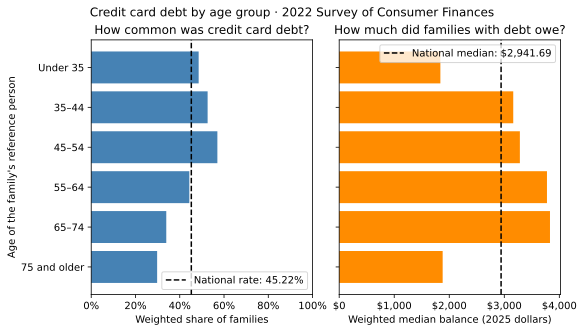

In [48]:
#Display and save the age comparison as an SVG
import matplotlib.pyplot as plt
from IPython.display import SVG, display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

fig, (ax_rate, ax_balance) = plt.subplots(
    1, 2, figsize=(8, 4.5), sharey=True, layout="constrained"
)

age_groups = age_summary.index

ax_rate.barh(
    age_groups, age_summary["Carrying credit card debt (%)"],
    color="steelblue"
)
ax_rate.axvline(
    national_debt_rate, color="black", linestyle="--",
    label=f"National rate: {national_debt_rate:.2f}%"
)
ax_rate.set_title("How common was credit card debt?")
ax_rate.set_xlabel("Weighted share of families")
ax_rate.set_ylabel("Age of the family's reference person")
ax_rate.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax_rate.set_xlim(0, 100)
ax_rate.invert_yaxis()
ax_rate.legend(loc="lower right")

ax_balance.barh(
    age_groups, age_summary["Weighted median balance ($)"],
    color="darkorange"
)
ax_balance.axvline(
    national_median_balance, color="black", linestyle="--",
    label=f"National median: \${national_median_balance:,.2f}"
)
ax_balance.set_title("How much did families with debt owe?")
ax_balance.set_xlabel("Weighted median balance (2025 dollars)")
ax_balance.xaxis.set_major_formatter(StrMethodFormatter("\${x:,.0f}"))
ax_balance.set_xlim(left=0)
ax_balance.legend(loc="upper right")

fig.suptitle("Credit card debt by age group · 2022 Survey of Consumer Finances")

svg_path = "credit_card_debt_by_age.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=svg_path))



>> The age chart shows two different peaks. Families with a reference person aged 45–54 were most likely to carry credit card debt (57.00%). Among families carrying debt, those in the 65–74 group had the highest weighted median balance ($3,830.32 in 2025 dollars).

In [49]:
#Check sample sizes for the combined age and income analysis
age_income_counts = (
    analysis_df.groupby(
        ["Age group", "Income band", "Imputation"], observed=True
    )
    .size()
    .unstack("Imputation", fill_value=0)
    .reindex(columns=range(1, 6), fill_value=0)
)

minimum_group_size = age_income_counts.min(axis=1)

display(
    minimum_group_size.unstack("Income band")
    .reindex(age_summary.index)
    .fillna(0)
    .astype(int)
)

Income band,"Under $25,000","$25,000 to under $50,000","$50,000 to under $100,000","$100,000 to under $200,000","$200,000 and above"
Age group,,,,,
Under 35,96,153,174,125,51
35–44,51,141,193,183,183
45–54,68,100,180,178,277
55–64,124,126,162,171,429
65–74,105,124,158,139,324
75 and older,81,74,98,60,185


All 30 age–income groups meet the draft’s cutoff of at least 30 families in every imputation. The smallest group has 51 families in its smallest imputation,

In [50]:
#Calculate the weighted debt rate by age and income
age_income_weights = (
    analysis_df.groupby(
        ["Age group", "Income band", "Imputation"], observed=True
    )[["WGT", "Weight for families with debt"]].sum()
)

age_income_rates = (
    100 * age_income_weights["Weight for families with debt"]
    / age_income_weights["WGT"]
).unstack("Imputation")

age_income_summary = (
    age_income_rates.mean(axis=1)
    .where(minimum_group_size.ge(30))
    .unstack("Income band")
    .reindex(index=age_summary.index, columns=income_summary.index)
)

display(age_income_summary.round(2))

Income band,"Under $25,000","$25,000 to under $50,000","$50,000 to under $100,000","$100,000 to under $200,000","$200,000 and above"
Age group,,,,,
Under 35,31.68,51.78,53.27,57.02,25.35
35–44,24.06,38.65,65.21,62.43,39.12
45–54,32.99,46.27,67.32,70.20,44.60
55–64,28.18,55.89,57.49,50.78,25.38
65–74,28.38,38.66,39.86,33.08,23.75
75 and older,28.60,38.96,32.15,21.37,13.55


>>The highest estimated debt rate in the table is 70.20% for families with a reference person aged 45–54 and income of $100,000 to under $200,000. The lowest is 13.55% for the 75 and older group in the $200,000 and above band.

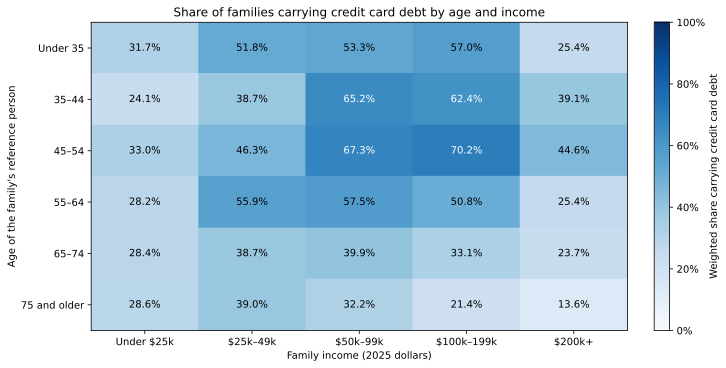

In [51]:
#Display the age-by-income heatmap as an SVG
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

heatmap = ax.imshow(
    age_income_summary.to_numpy(),
    cmap="Blues", vmin=0, vmax=100, aspect="auto"
)

ax.set_xticks(
    range(len(age_income_summary.columns)),
    ["Under $25k", "$25k–49k", "$50k–99k", "$100k–199k", "$200k+"]
)
ax.set_yticks(range(len(age_income_summary.index)), age_income_summary.index)

for row, rates in enumerate(age_income_summary.to_numpy()):
    for col, rate in enumerate(rates):
        label = "—" if pd.isna(rate) else f"{rate:.1f}%"
        color = "white" if rate >= 60 else "black"
        ax.text(col, row, label, ha="center", va="center", color=color)

ax.set_title("Share of families carrying credit card debt by age and income")
ax.set_xlabel("Family income (2025 dollars)")
ax.set_ylabel("Age of the family's reference person")

colorbar = fig.colorbar(heatmap, ax=ax, format=PercentFormatter(xmax=100))
colorbar.set_label("Weighted share carrying credit card debt")

svg_path = "credit_card_debt_by_age_and_income.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=svg_path))

>>The heatmap shows the combined age and income analysis. For families earning $100,000 to under $200,000, the estimated share carrying credit card debt was 70.2% in the 45–54 group and 21.4% in the 75 and older group.

In [52]:
#We already checked the education codes across the full dataset.
#This cell shows how many families are in each education group within each imputation, 
#so we can apply the same 30-family cutoff before calculating weighted debt rates.

#Start the education comparison
analysis_df["Education group"] = analysis_df["EDCL"].map(education_labels)

education_counts_by_imputation = (
    analysis_df.groupby(["Education group", "Imputation"])
    .size()
    .unstack("Imputation", fill_value=0)
    .reindex(list(education_labels.values()))
)

display(education_counts_by_imputation)

Imputation,1,2,3,4,5
Education group,,,,,
No high school diploma,428,429,431,430,428
High school diploma,907,905,904,903,903
Some college,986,988,987,988,990
College degree,2274,2273,2273,2274,2274


>>Within each education group and imputation, we divide the total survey weight of families carrying credit card debt by the total survey weight of all families in that group. The output shows four education groups and five percentage columns.
>>

In [ ]:
#Show the education-group counts as an SVG
#This chart uses imputation 1 to show the sample size, with each family counted once.


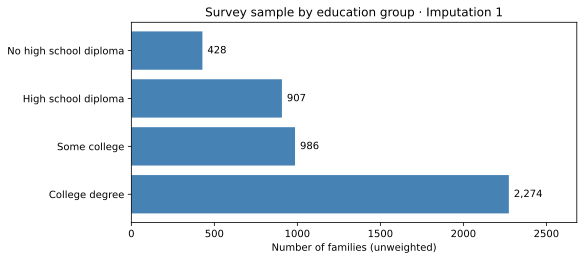

In [53]:

from IPython.display import SVG, display

education_sample = education_counts_by_imputation[1]

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")

bars = ax.barh(education_sample.index, education_sample, color="steelblue")
ax.bar_label(bars, labels=[f"{count:,}" for count in education_sample], padding=5)
ax.invert_yaxis()
ax.set_xlim(0, education_sample.max() * 1.18)
ax.set_title("Survey sample by education group · Imputation 1")
ax.set_xlabel("Number of families (unweighted)")

svg_path = "education_group_sample_counts.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.close(fig)

display(SVG(filename=svg_path))

The SVG shows the unweighted sample counts for imputation 1. All four education groups passed the sample-size check across the five imputations, so we can now compare their weighted debt rates.

In [54]:
#Calculate the weighted debt rate by education
education_weighted_totals = analysis_df.groupby(
    ["Education group", "Imputation"]
)[["WGT", "Weight for families with debt"]].sum()

education_debt_rates = (
    100 * education_weighted_totals["Weight for families with debt"]
    / education_weighted_totals["WGT"]
).unstack("Imputation").reindex(education_counts_by_imputation.index)

display(education_debt_rates.round(2))

Imputation,1,2,3,4,5
Education group,,,,,
No high school diploma,34.16,33.96,34.25,33.85,34.21
High school diploma,48.56,48.34,48.32,48.43,48.04
Some college,51.02,50.81,50.66,50.65,50.69
College degree,42.56,41.73,42.08,42.03,42.54


>>The output shows four education groups and five percentage columns.

In [55]:
#Average the five debt rates for each education group
education_summary = education_debt_rates.mean(axis=1).to_frame(
    "Carrying credit card debt (%)"
)

education_summary["Difference from national rate (pp)"] = (
    education_summary["Carrying credit card debt (%)"] - national_debt_rate
)

display(education_summary.round(2))

,Carrying credit card debt (%),Difference from national rate (pp)
Education group,,
No high school diploma,34.09,-11.14
High school diploma,48.34,3.12
Some college,50.77,5.54
College degree,42.19,-3.03


>>Carrying credit card debt (%)	Difference from national rate (pp)
Education group		
No high school diploma	34.09	-11.14
High school diploma	48.34	3.12
Some college	50.77	5.54
College degree	42.19	-3.03


In [56]:
#Calculate the weighted median balance by education
#We reuse weighted_median_balance() to find the typical balance among families carrying debt in each education group.
education_median_balances = (
    analysis_df.groupby(["Education group", "Imputation"])[
        ["CCBAL", "WGT", "Has credit card debt"]
    ]
    .apply(weighted_median_balance)
    .unstack("Imputation")
    .reindex(education_summary.index)
)

display(education_median_balances.round(2))

Imputation,1,2,3,4,5
Education group,,,,,
No high school diploma,1532.13,1422.69,1554.02,1532.13,1422.69
High school diploma,2188.76,2188.76,2188.76,2188.76,2188.76
Some college,3283.14,3283.14,3283.14,3283.14,3283.14
College degree,3578.62,3611.45,3611.45,3502.01,3502.01


The output will show four education groups and five median estimates per group, in 2025 dollars.

In [57]:
#Add median balances to the education summary
education_summary["Weighted median balance ($)"] = (
    education_median_balances.mean(axis=1)
)

display(education_summary.round(2))


#mean(axis=1) averages the five weighted medians for each education group. 
#The table now shows how common credit card debt was alongside how much families carrying debt typically owed, in 2025 dollars.

,Carrying credit card debt (%),Difference from national rate (pp),Weighted median balance ($)
Education group,,,
No high school diploma,34.09,-11.14,1492.73
High school diploma,48.34,3.12,2188.76
Some college,50.77,5.54,3283.14
College degree,42.19,-3.03,3561.11


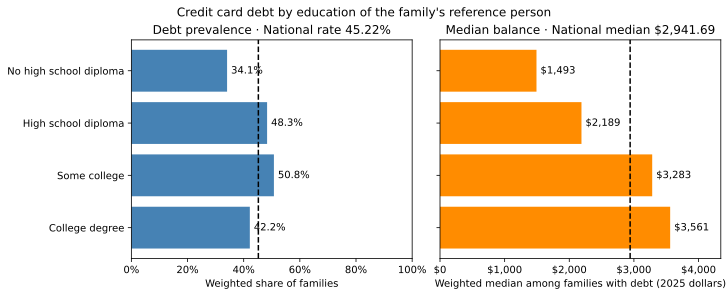

In [60]:
#Plot the education comparison as an SVG
fig, (ax_rate, ax_balance) = plt.subplots(
    1, 2, figsize=(10, 4), sharey=True, layout="constrained"
)

groups = education_summary.index
rates = education_summary["Carrying credit card debt (%)"]
balances = education_summary["Weighted median balance ($)"]

rate_bars = ax_rate.barh(groups, rates, color="steelblue")
ax_rate.bar_label(rate_bars, fmt="%.1f%%", padding=4)
ax_rate.axvline(national_debt_rate, color="black", linestyle="--")
ax_rate.set_title(f"Debt prevalence · National rate {national_debt_rate:.2f}%")
ax_rate.set_xlabel("Weighted share of families")
ax_rate.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax_rate.set_xlim(0, 100)
ax_rate.invert_yaxis()

balance_bars = ax_balance.barh(groups, balances, color="darkorange")
ax_balance.bar_label(
    balance_bars, labels=[f"${value:,.0f}" for value in balances], padding=4
)
ax_balance.axvline(national_median_balance, color="black", linestyle="--")
ax_balance.set_title(f"Median balance · National median ${national_median_balance:,.2f}")
ax_balance.set_xlabel("Weighted median among families with debt (2025 dollars)")
ax_balance.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax_balance.set_xlim(0, balances.max() * 1.22)
ax_balance.set_xticks([0, 1_000, 2_000, 3_000, 4_000])

fig.suptitle("Credit card debt by education of the family's reference person")

svg_path = "credit_card_debt_by_education.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=svg_path))

The chart compares credit card debt by the education level of the family’s reference person. Each row shows two measures for the same education group.
- Left — How common was credit card debt? The Some college group had the highest estimated share carrying debt (50.8%), compared with 45.22% nationally.
- Right — How much did families with debt typically owe? The College degree group had the highest weighted median balance ($3,561 in 2025 dollars), compared with $2,941.69 nationally. This measure includes only families carrying credit card debt.
The dashed lines mark the national estimates. For example, the college-degree group is below the national line on the left (42.2%) and above it on the right ($3,561). This shows why the two measures are useful together. Credit card debt was less common in that group than nationwide, and families in the group who carried debt typically owed more. These are descriptive survey comparisons.

>>Credit card debt was most common among families earning $50,000 to under $100,000 (53.43%) and among families with a reference person aged 45–54 (57.00%). Among families carrying debt, the highest estimated median balances were in the $200,000 and above income group ($5,713) and the 65–74 age group ($3,830), in 2025 dollars.
>>

## Compare credit card debt by income and age

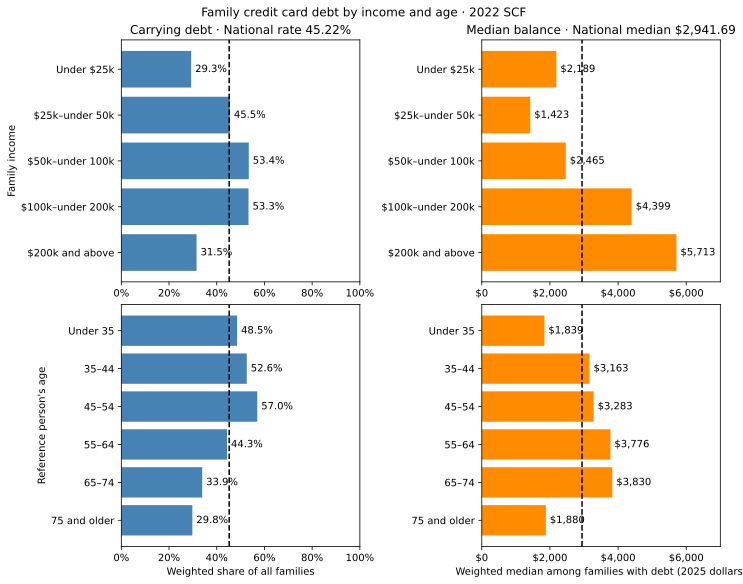

In [62]:
import matplotlib.pyplot as plt
from IPython.display import SVG, display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")

income_labels_short = [
    "Under $25k", "$25k–under 50k", "$50k–under 100k",
    "$100k–under 200k", "$200k and above"
]

for row, summary, labels, group_name in [
    (0, income_summary, income_labels_short, "Family income"),
    (1, age_summary, age_summary.index, "Reference person's age")
]:
    ax_rate, ax_balance = axes[row]
    rates = summary["Carrying credit card debt (%)"]
    balances = summary["Weighted median balance ($)"]

    rate_bars = ax_rate.barh(labels, rates, color="steelblue")
    ax_rate.bar_label(rate_bars, fmt="%.1f%%", padding=4)
    ax_rate.axvline(national_debt_rate, color="black", linestyle="--")
    ax_rate.set_xlim(0, 100)
    ax_rate.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax_rate.set_ylabel(group_name)
    ax_rate.invert_yaxis()

    balance_bars = ax_balance.barh(labels, balances, color="darkorange")
    ax_balance.bar_label(
        balance_bars, labels=[f"${value:,.0f}" for value in balances], padding=4
    )
    ax_balance.axvline(national_median_balance, color="black", linestyle="--")
    ax_balance.set_xlim(0, 7_000)
    ax_balance.set_xticks([0, 2_000, 4_000, 6_000])
    ax_balance.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax_balance.invert_yaxis()

axes[0, 0].set_title(f"Carrying debt · National rate {national_debt_rate:.2f}%")
axes[0, 1].set_title(f"Median balance · National median ${national_median_balance:,.2f}")
axes[1, 0].set_xlabel("Weighted share of all families")
axes[1, 1].set_xlabel("Weighted median among families with debt (2025 dollars)")

fig.suptitle("Family credit card debt by income and age · 2022 SCF")

svg_path = "credit_card_debt_conclusion.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=svg_path))


>>The chart answers two questions about U.S. families in the 2022 Survey of Consumer Finances. The blue bars show the estimated percentage of all families in each group carrying credit card debt. The orange bars show the weighted median balance among families in that group who carried debt, in 2025 dollars. The dashed lines mark the national estimates of 45.22% and $2,941.69, respectively.
>>
>>
>>Top left - How common was debt by income?	- The two middle-income bands had nearly identical rates, 53.4% for $50,000 to under $100,000 and 53.3% for $100,000 to under $200,000. Both were about 8 percentage points above the national rate. The lowest and highest income bands were below it, at 29.3% and 31.5%.

>>Top right - How much did families with debt owe by income?	The $200,000 and above group had the highest median balance ($5,713), followed by the $100,000 to under $200,000 group ($4,399). Those were the only two income bands above the national median.
>>
>>Bottom left · How common was debt by age?	The debt rate peaked at 57.0% among families whose reference person was aged 45–54. Rates were lower in each older age group, reaching 29.8% for ages 75 and older.
>>
>>Bottom right · How much did families with debt owe by age?
>>The 65–74 group had the highest median balance ($3,830), followed closely by 55–64 ($3,776). The under 35 and 75 and older groups had medians below $1,900.
>>
>>

The groups where debt was most common differed from the groups where families with debt typically owed the most. For example, 31.5% of families earning $200,000 or more carried credit card debt, and among those who did, the median balance was $5,713. The same pattern appears by age. The 65–74 group had a below-national debt rate (33.9%) and an above-national median balance ($3,830) among families carrying debt.

# Why Imputation Was Used
The Federal Reserve filled in missing survey answers so families with incomplete responses could still be included. The public extract does not show how many answers were filled in.

Across the five versions, the estimated national debt rate ranged from 45.02% to 45.52%, and the weighted median balance among families with debt ranged from 2,889 to 2,955 dollars. This shows modest variation across the five versions. The effect compared with using only originally reported answers remains unknown.

# Summary plot — National estimates and the highest groups

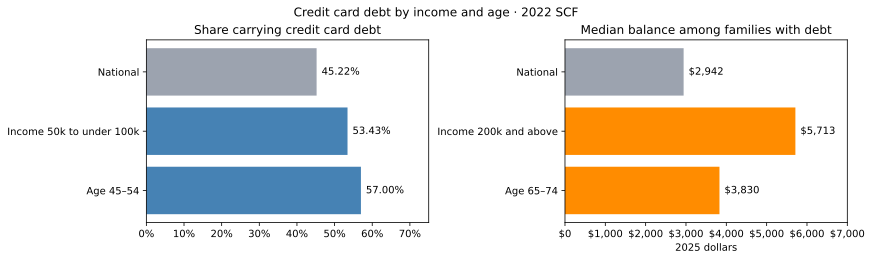

In [63]:
import matplotlib.pyplot as plt
from IPython.display import SVG, display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

rate_col = "Carrying credit card debt (%)"
balance_col = "Weighted median balance ($)"

fig, (ax_rate, ax_balance) = plt.subplots(
    1, 2, figsize=(12, 3.5), layout="constrained"
)

rate_values = [
    national_debt_rate,
    income_summary[rate_col].max(),
    age_summary[rate_col].max()
]
balance_values = [
    national_median_balance,
    income_summary[balance_col].max(),
    age_summary[balance_col].max()
]

rate_bars = ax_rate.barh(
    ["National", "Income 50k to under 100k", "Age 45–54"],
    rate_values,
    color=["#9CA3AF", "steelblue", "steelblue"]
)
ax_rate.bar_label(rate_bars, labels=[f"{v:.2f}%" for v in rate_values], padding=5)
ax_rate.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax_rate.set(xlim=(0, 75), title="Share carrying credit card debt")
ax_rate.invert_yaxis()

balance_bars = ax_balance.barh(
    ["National", "Income 200k and above", "Age 65–74"],
    balance_values,
    color=["#9CA3AF", "darkorange", "darkorange"]
)
ax_balance.bar_label(
    balance_bars, labels=[f"${v:,.0f}" for v in balance_values], padding=5
)
ax_balance.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax_balance.set(
    xlim=(0, 7_000),
    title="Median balance among families with debt",
    xlabel="2025 dollars"
)
ax_balance.invert_yaxis()

fig.suptitle("Credit card debt by income and age · 2022 SCF")

svg_path = "credit_card_debt_summary.svg"
fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename=svg_path))

# Conclusion
Using the 2022 Survey of Consumer Finances, this analysis estimated that 45.22% of U.S. families carried credit card debt. Among families carrying debt, the national weighted median balance was 2,941.69 dollars.

Credit card debt was most common in the two income bands from 50,000 to under 200,000 dollars, both at about 53%. The 50,000 to under 100,000 dollar band had the highest estimated rate at 53.43%. By age, the rate peaked at 57.00% among families whose reference person was 45–54 years old.

The groups where debt was most common differed from those where families with debt typically owed the most. Among families carrying debt, the highest estimated median balances were 5,713 dollars for families earning 200,000 dollars or more and 3,830 dollars for families whose reference person was 65–74 years old. All dollar amounts are expressed in 2025 dollars, and the estimates describe patterns from the 2022 survey.